# Ray Serve: compose two deployments

A Greeter deployment is passed into a Driver deployment with .bind(); serve.run starts both as one application.

**When to use it.** Model composition: a front deployment that calls one or more back-end deployments through handles.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

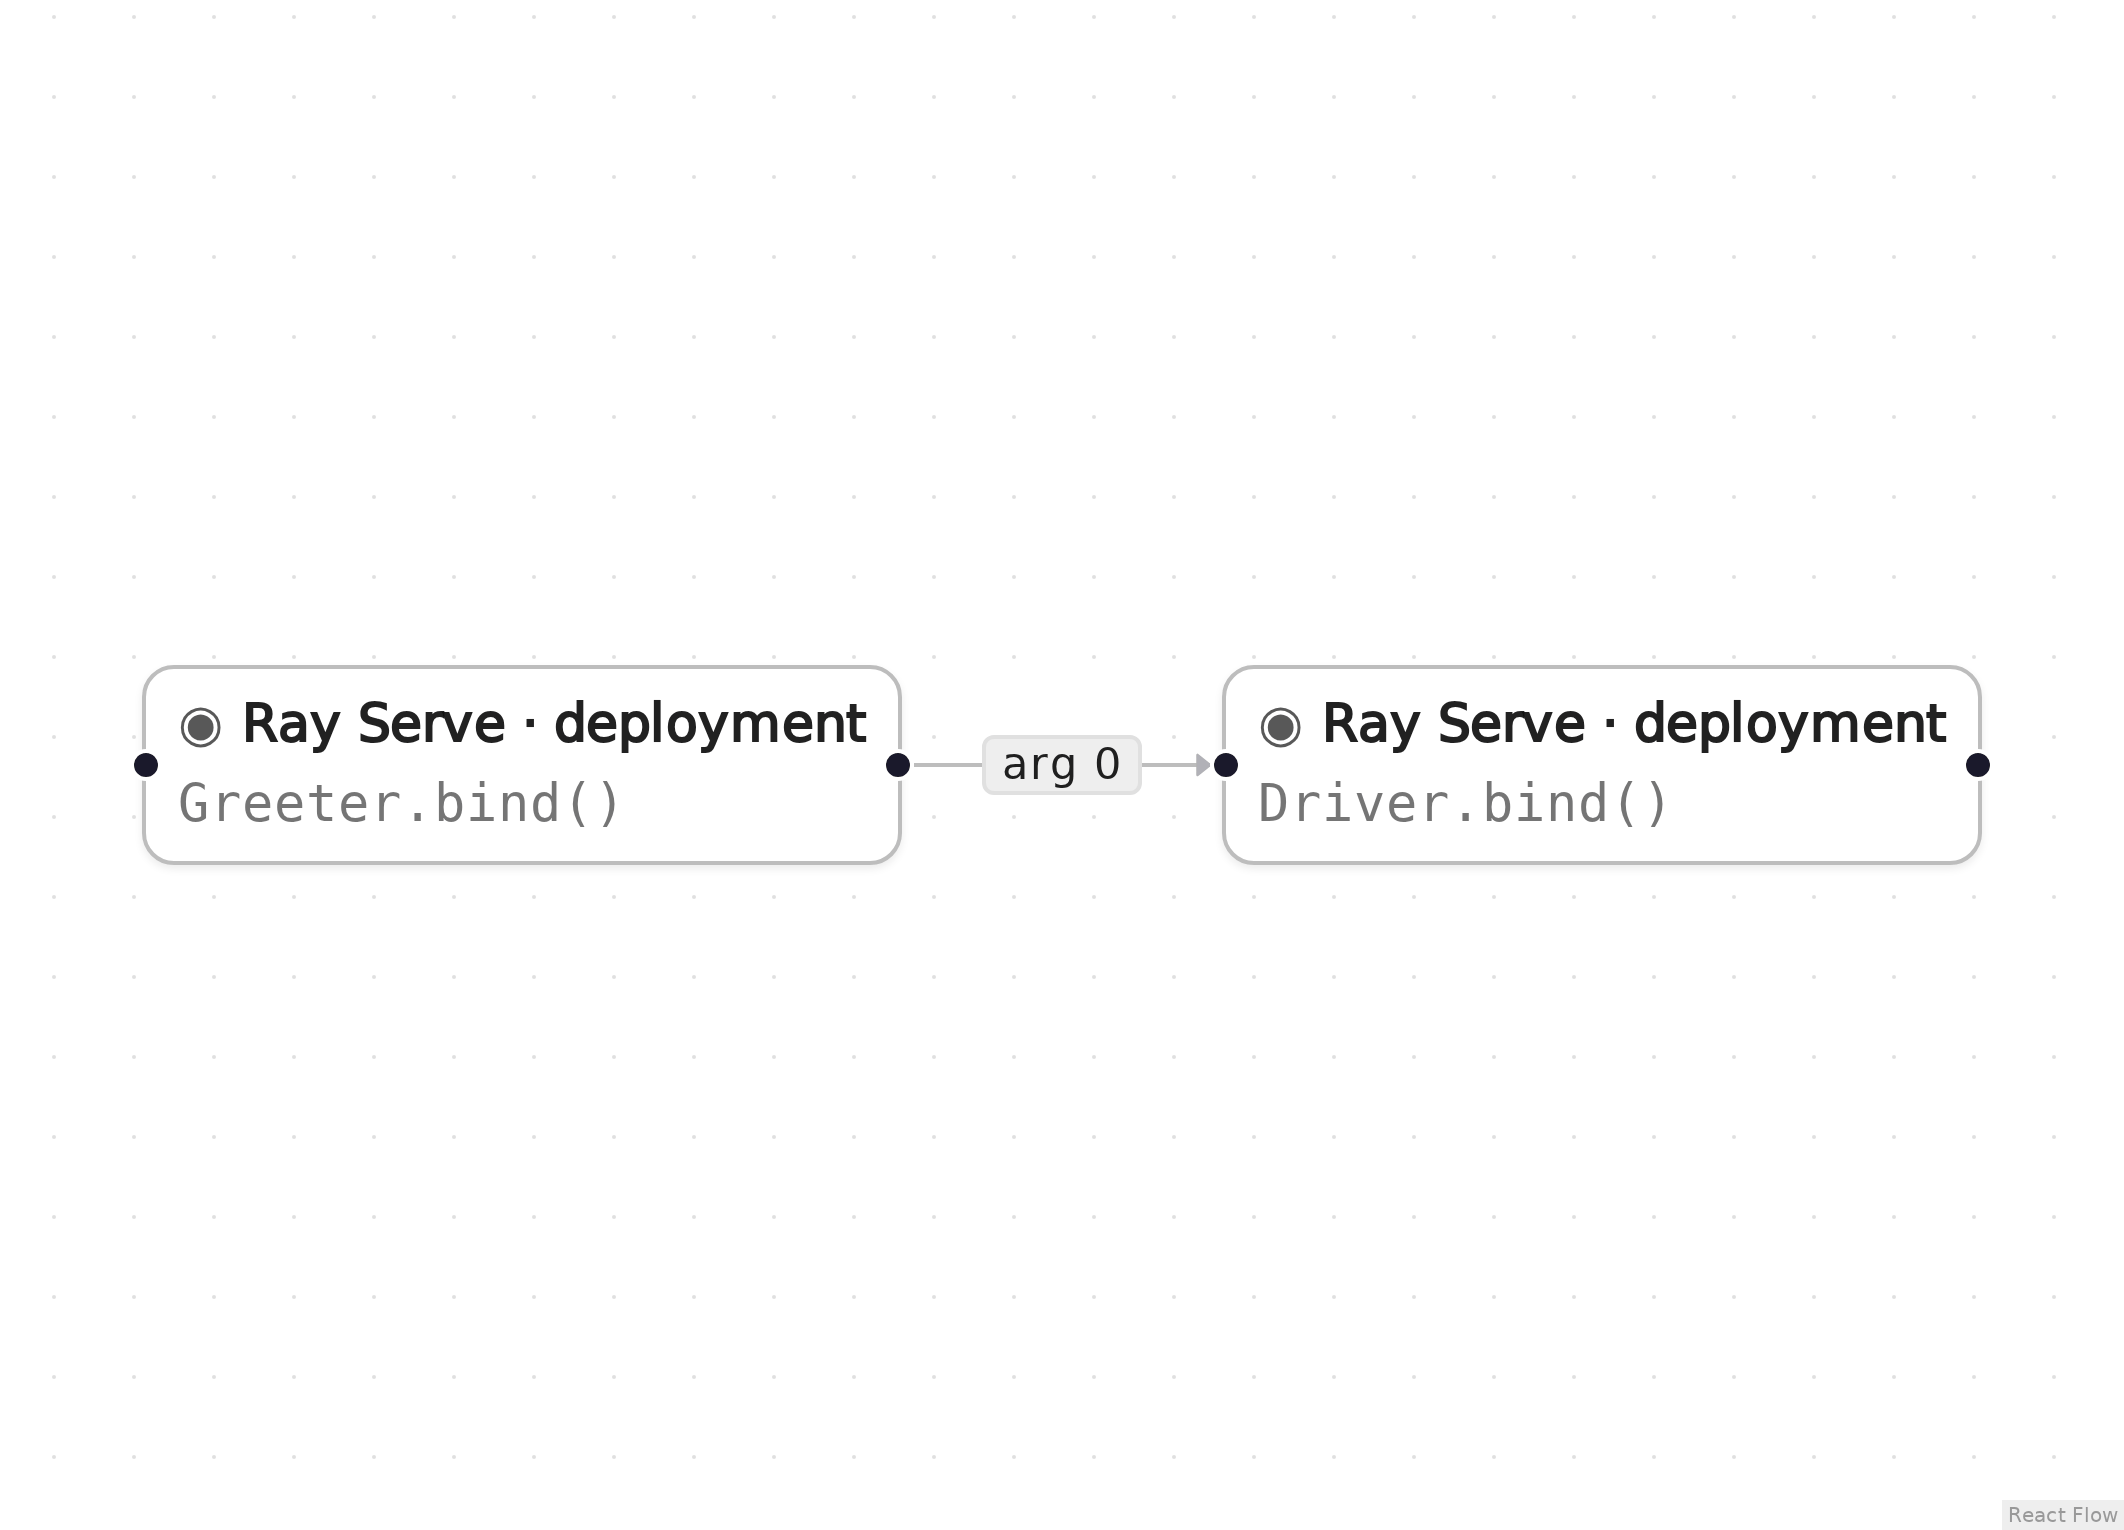

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
from ray import serve


@serve.deployment
class Greeter:
    async def __call__(self, x):
        return f"hi {x}"


@serve.deployment
class Driver:
    def __init__(self, greeter):
        self.greeter = greeter  # a DeploymentHandle to Greeter

    async def __call__(self, x):
        return await self.greeter.remote(x)

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray

if not ray.is_initialized():
    ray.init()

_deploy_n1 = Greeter.bind()
_deploy_n2 = Driver.bind(_deploy_n1)
serve.run(_deploy_n2)

DeploymentHandle(deployment='Driver')

## Check the result

The cell below checks that the generated code did what the graph describes. A Jupyter kernel already runs an asyncio event loop, so this cell awaits the Serve responses; in a plain Python script you would call `.result()` on them instead.

In [4]:
handle = serve.get_app_handle("default")
result = await handle.remote("bob")
assert result == "hi bob", result
print("result =", result)

result = hi bob


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Deployment** (node `n1`, line 9)

```python
_deploy_n1 = Greeter.bind()
```

Greeter.bind() declares the deployment without starting it.

**Deployment** (node `n2`, lines 10–11)

```python
_deploy_n2 = Driver.bind(_deploy_n1)
serve.run(_deploy_n2)
```

Driver.bind(_deploy_n1) passes Greeter in; at run time Driver receives a DeploymentHandle to it. serve.run deploys the whole application.

## Other ways the builder can emit this graph

The builder can emit the same graph in other forms. They are shown here as text and are not run by this notebook.

### As a standalone script (`serve_greeter_driver.py`)

The builder can export the graph as a Python module: the user functions are copied in and the Ray calls go under `if __name__ == "__main__":`. It was not run here.

```python
# Generated with Eugo's visual Ray builder

# Best-effort standalone export: cells defining referenced functions/classes
# were inlined. Transitive helpers from OTHER cells, referenced notebook VARIABLES
# (e.g. a Data source's `df`), and notebook magics (commented out) may need manual
# edits. Re-exporting overwrites this file.

from ray import serve
import ray

from ray import serve


@serve.deployment
class Greeter:
    async def __call__(self, x):
        return f"hi {x}"


@serve.deployment
class Driver:
    def __init__(self, greeter):
        self.greeter = greeter  # a DeploymentHandle to Greeter

    async def __call__(self, x):
        return await self.greeter.remote(x)

if __name__ == "__main__":
    ray.init()

    _deploy_n1 = Greeter.bind()
    _deploy_n2 = Driver.bind(_deploy_n1)
    serve.run(_deploy_n2, blocking=True)
```

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [5]:
from ray import serve

serve.shutdown()
ray.shutdown()